In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import files

uploaded = files.upload()

Saving ecommerce_sales_34500.xlsx to ecommerce_sales_34500.xlsx


In [3]:
import pandas as pd

df = pd.read_excel("ecommerce_sales_34500.xlsx")

In [4]:
df.head()

,order_id,customer_id,product_id,category,price,discount,quantity,payment_method,order_date,delivery_time_days,region,returned,total_amount,shipping_cost,profit_margin,customer_age,customer_gender
0,O100000,C17270,P234890,Home,164.08,0.15,1,Credit Card,2023-12-23,4,West,No,139.47,7.88,31.17,60,Female
1,O100001,C17603,P228204,Grocery,24.73,0.00,1,Credit Card,2025-04-03,6,South,No,24.73,4.60,-2.62,37,Male
2,O100002,C10860,P213892,Electronics,175.58,0.05,1,Credit Card,2024-10-08,4,North,No,166.80,6.58,13.44,34,Male
3,O100003,C15390,P208689,Electronics,63.67,0.00,1,UPI,2024-09-14,6,South,No,63.67,5.50,2.14,21,Female
4,O100004,C15226,P228063,Home,16.33,0.15,1,COD,2024-12-21,6,East,No,13.88,2.74,1.15,39,Male


In [5]:
df.shape

(34500, 17)

In [6]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'category', 'price',
       'discount', 'quantity', 'payment_method', 'order_date',
       'delivery_time_days', 'region', 'returned', 'total_amount',
       'shipping_cost', 'profit_margin', 'customer_age', 'customer_gender'],
      dtype='object')

In [7]:
df.isnull().sum()

,0
order_id,0
customer_id,0
product_id,0
category,0
price,0
discount,0
quantity,0
payment_method,0
order_date,0
delivery_time_days,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,price,discount,quantity,order_date,delivery_time_days,total_amount,shipping_cost,profit_margin,customer_age
count,34500.000000,34500.000000,34500.000000,34500,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000
mean,119.391632,0.049291,1.490725,2024-09-13 13:39:17.843478272,4.814203,170.008494,6.152120,28.116505,43.474377
min,1.010000,0.000000,1.000000,2023-09-12 00:00:00,3.000000,0.820000,0.000000,-6.200000,18.000000
25%,16.690000,0.000000,1.000000,2024-03-14 00:00:00,4.000000,19.710000,4.420000,1.500000,31.000000
50%,45.660000,0.000000,1.000000,2024-09-16 00:00:00,5.000000,56.820000,6.090000,10.550000,43.000000
75%,130.950000,0.100000,2.000000,2025-03-17 00:00:00,6.000000,168.530000,7.830000,33.132500,56.000000
max,2930.470000,0.300000,5.000000,2025-09-11 00:00:00,13.000000,12931.800000,15.650000,1536.170000,69.000000
std,195.620477,0.069894,0.932270,NaN,1.242141,357.503014,2.389539,53.352947,14.980682


In [10]:
df["customer_id"].nunique()

7903

In [11]:
df.columns.tolist()

['order_id',
 'customer_id',
 'product_id',
 'category',
 'price',
 'discount',
 'quantity',
 'payment_method',
 'order_date',
 'delivery_time_days',
 'region',
 'returned',
 'total_amount',
 'shipping_cost',
 'profit_margin',
 'customer_age',
 'customer_gender']

In [12]:
df[['returned', 'customer_gender', 'customer_age',
    'total_amount', 'quantity', 'discount',
    'profit_margin']].head(10)

,returned,customer_gender,customer_age,total_amount,quantity,discount,profit_margin
0,No,Female,60,139.47,1,0.15,31.17
1,No,Male,37,24.73,1,0.00,-2.62
2,No,Male,34,166.80,1,0.05,13.44
3,No,Female,21,63.67,1,0.00,2.14
4,No,Male,39,13.88,1,0.15,1.15
5,No,Female,35,97.04,2,0.10,37.35
6,No,Male,49,266.50,1,0.00,22.88
7,No,Other,66,9.98,1,0.00,-0.02
8,No,Female,37,6.28,1,0.05,-1.23
9,No,Male,56,10.91,1,0.00,-1.89


In [13]:
customer_df = df.groupby('customer_id').agg(
    total_spending=('total_amount', 'sum'),
    purchase_frequency=('order_id', 'count'),
    avg_order_value=('total_amount', 'mean'),
    total_quantity=('quantity', 'sum'),
    avg_discount=('discount', 'mean'),
    avg_profit_margin=('profit_margin', 'mean'),
    avg_delivery_time=('delivery_time_days', 'mean'),
    customer_age=('customer_age', 'first'),
    customer_gender=('customer_gender', 'first')
).reset_index()

In [14]:
customer_df.head()


,customer_id,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age,customer_gender
0,C10000,210.58,2,105.290000,2,0.075000,9.855000,4.000000,54,Male
1,C10001,3246.02,5,649.204000,12,0.070000,98.780000,4.800000,24,Female
2,C10002,216.85,5,43.370000,6,0.130000,6.278000,5.200000,51,Other
3,C10003,154.30,3,51.433333,3,0.016667,8.760000,5.000000,38,Male
4,C10004,716.99,3,238.996667,5,0.000000,27.566667,5.666667,22,Female


In [15]:
customer_df.shape

(7903, 10)

In [16]:
customer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7903 entries, 0 to 7902
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         7903 non-null   object 
 1   total_spending      7903 non-null   float64
 2   purchase_frequency  7903 non-null   int64  
 3   avg_order_value     7903 non-null   float64
 4   total_quantity      7903 non-null   int64  
 5   avg_discount        7903 non-null   float64
 6   avg_profit_margin   7903 non-null   float64
 7   avg_delivery_time   7903 non-null   float64
 8   customer_age        7903 non-null   int64  
 9   customer_gender     7903 non-null   object 
dtypes: float64(5), int64(3), object(2)
memory usage: 617.6+ KB


In [17]:
customer_df.describe()

,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age
count,7903.000000,7903.000000,7903.000000,7903.000000,7903.000000,7903.000000,7903.000000,7903.000000
mean,742.160325,4.365431,169.313693,6.507655,0.049464,28.059340,4.815942,43.706947
std,827.178631,2.048718,188.222659,3.653793,0.039143,28.569140,0.688531,15.077020
min,1.240000,1.000000,1.240000,1.000000,0.000000,-4.200000,3.000000,18.000000
25%,215.885000,3.000000,60.245500,4.000000,0.021429,10.640357,4.333333,31.000000
50%,494.450000,4.000000,115.880000,6.000000,0.050000,20.570000,4.800000,44.000000
75%,972.460000,6.000000,209.103571,9.000000,0.070000,35.969464,5.222222,57.000000
max,13885.100000,13.000000,3791.860000,27.000000,0.300000,453.940000,10.000000,69.000000


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

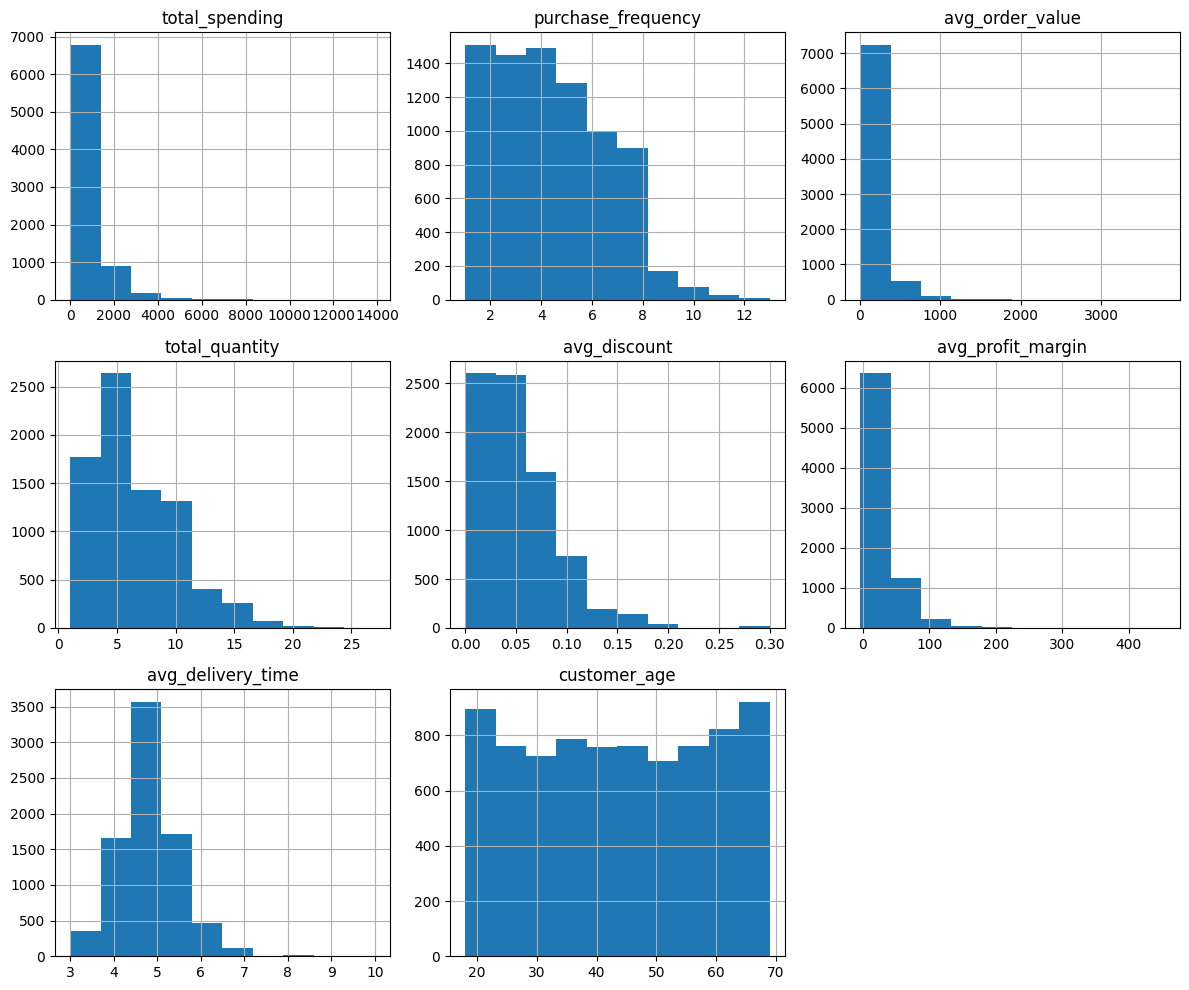

In [19]:
customer_df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

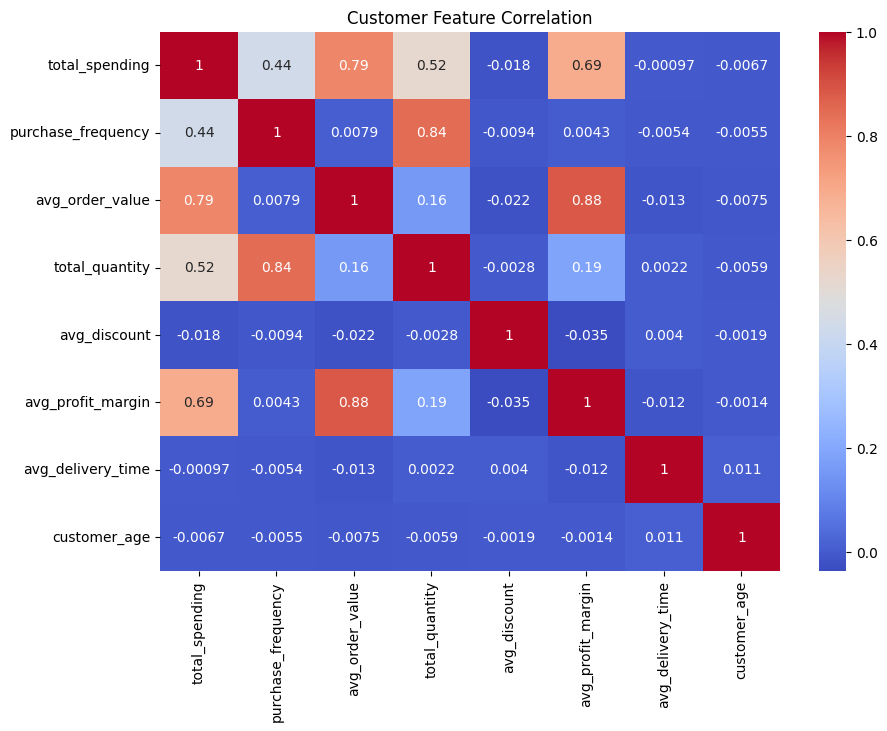

In [20]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    customer_df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Customer Feature Correlation")
plt.show()

In [21]:
#FEATURE SELECTION
features = [
    'total_spending',
    'purchase_frequency',
    'avg_order_value',
    'total_quantity',
    'avg_discount',
    'avg_profit_margin',
    'avg_delivery_time',
    'customer_age'
]

X = customer_df[features]

In [22]:
X.head()

,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age
0,210.58,2,105.290000,2,0.075000,9.855000,4.000000,54
1,3246.02,5,649.204000,12,0.070000,98.780000,4.800000,24
2,216.85,5,43.370000,6,0.130000,6.278000,5.200000,51
3,154.30,3,51.433333,3,0.016667,8.760000,5.000000,38
4,716.99,3,238.996667,5,0.000000,27.566667,5.666667,22


In [23]:
X.shape

(7903, 8)

In [24]:
#FEATURE SCALING
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [25]:
X_scaled[:5]

array([[-0.64268338, -1.15466376, -0.34017022, -1.23377021,  0.65241178,
        -0.63724326, -1.18512318,  0.68274131],
       [ 3.02717939,  0.30975922,  2.54974972,  1.50328514,  0.52466622,
         2.47557797, -0.02315516, -1.30716769],
       [-0.63510292,  0.30975922, -0.66916312, -0.13894807,  2.05761289,
        -0.76245621,  0.55782885,  0.48375041],
       [-0.7107262 , -0.66652277, -0.62632108, -0.96006467, -0.83795304,
        -0.67557375,  0.26733684, -0.37854349],
       [-0.03043105, -0.66652277,  0.37023907, -0.41265361, -1.26377156,
        -0.01724605,  1.23564353, -1.43982829]])

In [26]:
#K-MEANS CLUSTERING
#1. ELBOW METHOD
from sklearn.cluster import KMeans

wcss = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

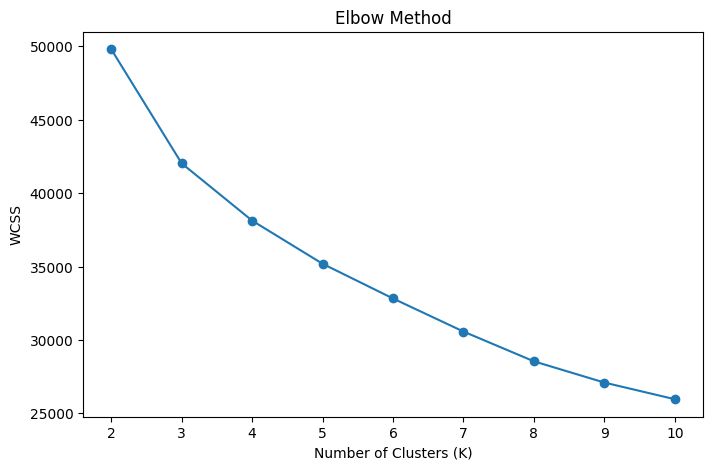

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [28]:
#SILHOUTE SCORE
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

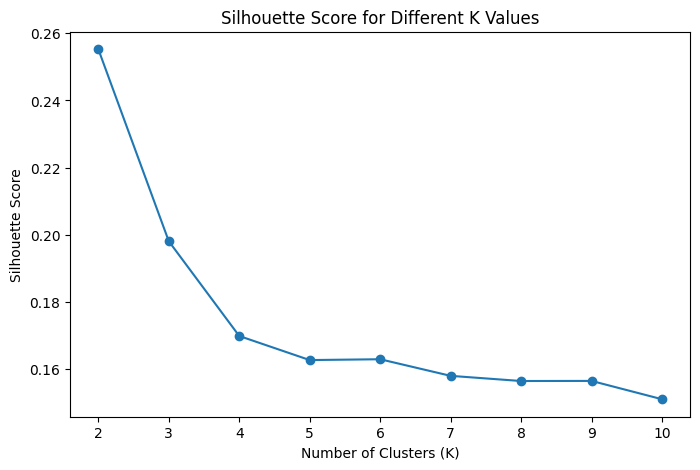

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.show()

In [30]:
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.2553
K = 3: Silhouette Score = 0.1981
K = 4: Silhouette Score = 0.1698
K = 5: Silhouette Score = 0.1627
K = 6: Silhouette Score = 0.1629
K = 7: Silhouette Score = 0.1580
K = 8: Silhouette Score = 0.1564
K = 9: Silhouette Score = 0.1565
K = 10: Silhouette Score = 0.1510


In [31]:
#TRAIN K-MEANS
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

customer_df['cluster'] = kmeans.fit_predict(X_scaled)

In [32]:
customer_df.head()

,customer_id,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age,customer_gender,cluster
0,C10000,210.58,2,105.290000,2,0.075000,9.855000,4.000000,54,Male,2
1,C10001,3246.02,5,649.204000,12,0.070000,98.780000,4.800000,24,Female,3
2,C10002,216.85,5,43.370000,6,0.130000,6.278000,5.200000,51,Other,2
3,C10003,154.30,3,51.433333,3,0.016667,8.760000,5.000000,38,Male,0
4,C10004,716.99,3,238.996667,5,0.000000,27.566667,5.666667,22,Female,0


In [33]:
customer_df['cluster'].value_counts().sort_index()

,count
cluster,
0,3048
1,2410
2,1808
3,637


In [34]:
#ANALYSE THE CLUSTERS
cluster_profile = customer_df.groupby('cluster')[
    ['total_spending',
     'purchase_frequency',
     'avg_order_value',
     'total_quantity',
     'avg_discount',
     'avg_profit_margin',
     'avg_delivery_time',
     'customer_age']
].mean()

cluster_profile

,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age
cluster,,,,,,,,
0,354.101972,3.178806,112.978574,4.285433,0.023164,19.629544,4.812385,44.020013
1,1047.381083,6.595021,162.045828,10.335270,0.047138,28.162271,4.820941,43.266805
2,375.146587,3.444690,110.236692,4.710177,0.097148,18.533736,4.816335,43.946350
3,2485.929042,4.221350,634.048728,7.761381,0.048772,95.042462,4.812933,43.194662


In [35]:
cluster_profile

,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age
cluster,,,,,,,,
0,354.101972,3.178806,112.978574,4.285433,0.023164,19.629544,4.812385,44.020013
1,1047.381083,6.595021,162.045828,10.335270,0.047138,28.162271,4.820941,43.266805
2,375.146587,3.444690,110.236692,4.710177,0.097148,18.533736,4.816335,43.946350
3,2485.929042,4.221350,634.048728,7.761381,0.048772,95.042462,4.812933,43.194662


In [36]:
#EVALUTION OF CLUSTER
from sklearn.metrics import silhouette_score

kmeans_silhouette = silhouette_score(
    X_scaled,
    customer_df['cluster']
)

print("K-Means Silhouette Score:", kmeans_silhouette)

K-Means Silhouette Score: 0.16984271837214096


In [37]:
from sklearn.metrics import davies_bouldin_score

db_index = davies_bouldin_score(
    X_scaled,
    customer_df['cluster']
)

print("Davies-Bouldin Index:", db_index)

Davies-Bouldin Index: 1.6890556035706976


In [38]:
print("WCSS:", wcss[4 - 2])

WCSS: 38126.267458372786


In [39]:
#DB Scan

In [40]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(X_scaled)

customer_df['dbscan_cluster'] = dbscan_labels

In [41]:
customer_df['dbscan_cluster'].value_counts().sort_index()

,count
dbscan_cluster,
-1,6732
0,9
1,13
2,12
3,72
...,...
96,4
97,7
98,4


In [42]:
#Tune DB Scan
from sklearn.cluster import DBSCAN
import numpy as np

eps_values = [0.5, 0.7, 0.9, 1.1, 1.3, 1.5]

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    print(f"eps = {eps}")
    print(f"Clusters = {n_clusters}")
    print(f"Noise points = {n_noise}")
    print("-" * 30)

eps = 0.5
Clusters = 101
Noise points = 6732
------------------------------
eps = 0.7
Clusters = 32
Noise points = 3270
------------------------------
eps = 0.9
Clusters = 16
Noise points = 1424
------------------------------
eps = 1.1
Clusters = 4
Noise points = 659
------------------------------
eps = 1.3
Clusters = 3
Noise points = 344
------------------------------
eps = 1.5
Clusters = 4
Noise points = 205
------------------------------


In [43]:
#for better clustering
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

eps_values = [1.1, 1.3, 1.5]

for eps in eps_values:

    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels = dbscan.fit_predict(X_scaled)

    # Remove noise points (-1) for evaluation
    mask = labels != -1

    X_valid = X_scaled[mask]
    labels_valid = labels[mask]

    n_clusters = len(set(labels_valid))

    print("eps =", eps)
    print("Clusters =", n_clusters)
    print("Noise points =", sum(labels == -1))

    if n_clusters >= 2:
        silhouette = silhouette_score(X_valid, labels_valid)
        db_index = davies_bouldin_score(X_valid, labels_valid)

        print("Silhouette Score =", silhouette)
        print("Davies-Bouldin Index =", db_index)

    print("-" * 40)

eps = 1.1
Clusters = 4
Noise points = 659
Silhouette Score = 0.2990821325379321
Davies-Bouldin Index = 0.7384973553994112
----------------------------------------
eps = 1.3
Clusters = 3
Noise points = 344
Silhouette Score = 0.47696124581961236
Davies-Bouldin Index = 0.4534858744379276
----------------------------------------
eps = 1.5
Clusters = 4
Noise points = 205
Silhouette Score = 0.4534744844434209
Davies-Bouldin Index = 0.4849825984751285
----------------------------------------


In [44]:
#Final DB Scan
from sklearn.cluster import DBSCAN

# Final DBSCAN model
dbscan = DBSCAN(
    eps=1.3,
    min_samples=5
)

# Fit DBSCAN
customer_df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

# Display cluster counts
print("DBSCAN Cluster Counts:")
print(customer_df['dbscan_cluster'].value_counts().sort_index())

DBSCAN Cluster Counts:
dbscan_cluster
-1     344
 0    7548
 1       6
 2       5
Name: count, dtype: int64


In [45]:
#PCA Visualization
from sklearn.decomposition import PCA

# Apply PCA to scaled features
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Reduced number of features:", X_pca.shape[1])

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Original number of features: 8
Reduced number of features: 2
Explained variance ratio:
[0.35971929 0.21211945]
Total explained variance: 0.5718387366203833


In [46]:
#K-Means PCA visualization

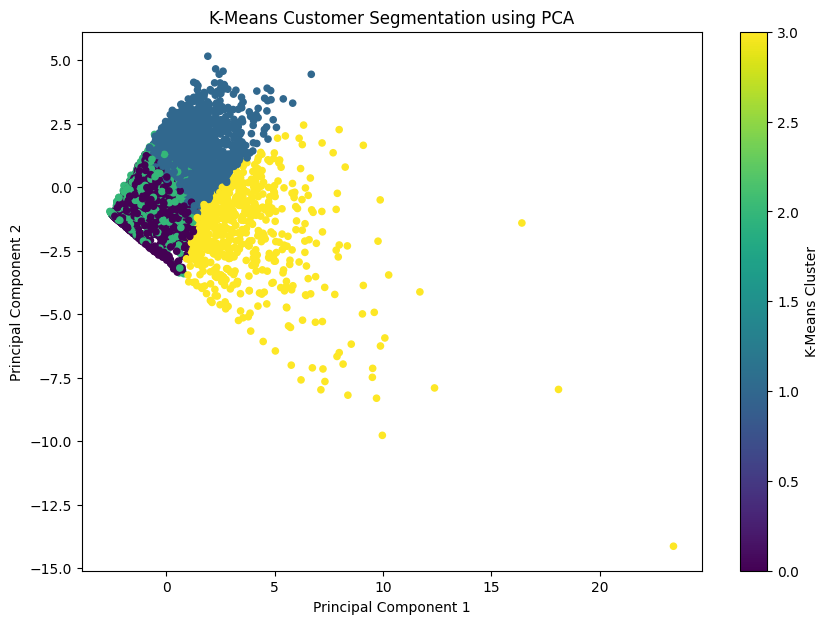

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=customer_df['cluster'],
    cmap='viridis',
    s=20
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Customer Segmentation using PCA')

plt.colorbar(label='K-Means Cluster')

plt.show()

In [48]:
cluster_profile

,total_spending,purchase_frequency,avg_order_value,total_quantity,avg_discount,avg_profit_margin,avg_delivery_time,customer_age
cluster,,,,,,,,
0,354.101972,3.178806,112.978574,4.285433,0.023164,19.629544,4.812385,44.020013
1,1047.381083,6.595021,162.045828,10.335270,0.047138,28.162271,4.820941,43.266805
2,375.146587,3.444690,110.236692,4.710177,0.097148,18.533736,4.816335,43.946350
3,2485.929042,4.221350,634.048728,7.761381,0.048772,95.042462,4.812933,43.194662


In [49]:
#K-Means evaluation metrics
from sklearn.metrics import silhouette_score, davies_bouldin_score

# K-Means evaluation
kmeans_silhouette = silhouette_score(
    X_scaled,
    customer_df['cluster']
)

kmeans_db = davies_bouldin_score(
    X_scaled,
    customer_df['cluster']
)

print("K-Means Silhouette Score:", kmeans_silhouette)
print("K-Means Davies-Bouldin Index:", kmeans_db)

K-Means Silhouette Score: 0.16984271837214096
K-Means Davies-Bouldin Index: 1.6890556035706976


In [50]:
comparison = pd.DataFrame({
    'Metric': [
        'Number of Clusters',
        'Noise Points',
        'Silhouette Score',
        'Davies-Bouldin Index',
        'WCSS'
    ],
    'K-Means': [
        4,
        0,
        kmeans_silhouette,
        kmeans_db,
        38126.267458372786
    ],
    'DBSCAN': [
        3,
        344,
        0.47696124581961236,
        0.4534858744379276,
        'Not Applicable'
    ]
})

comparison

,Metric,K-Means,DBSCAN
0,Number of Clusters,4.000000,3
1,Noise Points,0.000000,344
2,Silhouette Score,0.169843,0.476961
3,Davies-Bouldin Index,1.689056,0.453486
4,WCSS,38126.267458,Not Applicable


In [51]:
#Install Streamlit
!pip install streamlit pyngrok -q

In [52]:
import pickle
import pandas as pd

# Save customer data
with open("customer_data.pkl", "wb") as file:
    pickle.dump(customer_df, file)

# Save PCA data
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["cluster"] = customer_df["cluster"].values

pca_df.to_csv("pca_data.csv", index=False)

print("Customer data and PCA data saved successfully!")

Customer data and PCA data saved successfully!


In [53]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("customer_data.pkl exists:", os.path.exists("customer_data.pkl"))
print("pca_data.csv exists:", os.path.exists("pca_data.csv"))

app.py exists: False
customer_data.pkl exists: True
pca_data.csv exists: True


In [54]:
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Customer Segmentation Dashboard",
    page_icon="📊",
    layout="wide"
)

# --------------------------------------------------
# TITLE
# --------------------------------------------------

st.title("📊 Customer Segmentation Dashboard")
st.write("Customer segmentation using K-Means and DBSCAN clustering")

# --------------------------------------------------
# LOAD CUSTOMER DATA
# --------------------------------------------------

try:
    with open("customer_data.pkl", "rb") as file:
        customer_df = pickle.load(file)

    data = customer_df.copy()

except FileNotFoundError:
    st.error("customer_data.pkl file not found.")
    st.stop()

# --------------------------------------------------
# LOAD PCA DATA
# --------------------------------------------------

try:
    pca_data = pd.read_csv("pca_data.csv")

except FileNotFoundError:
    st.error("pca_data.csv file not found.")
    st.stop()

# --------------------------------------------------
# SEGMENT NAMES
# --------------------------------------------------

segment_names = {
    0: "Low-Value Occasional Customers",
    1: "Frequent High-Value Customers",
    2: "Discount-Sensitive Customers",
    3: "Premium High-Spending Customers"
}

data["segment_name"] = data["cluster"].map(segment_names)

# Add segment names to PCA data
pca_data["Segment"] = data["segment_name"].values

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.header("Dashboard Filters")

selected_segment = st.sidebar.selectbox(
    "Select Customer Segment",
    ["All"] + list(segment_names.values())
)

if selected_segment != "All":
    filtered_data = data[
        data["segment_name"] == selected_segment
    ]
else:
    filtered_data = data

# --------------------------------------------------
# KEY METRICS
# --------------------------------------------------

st.subheader("📌 Customer Overview")

col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric(
        "Total Customers",
        f"{len(filtered_data):,}"
    )

with col2:
    st.metric(
        "Total Spending",
        f"₹{filtered_data['total_spending'].sum():,.2f}"
    )

with col3:
    st.metric(
        "Avg Order Value",
        f"₹{filtered_data['avg_order_value'].mean():,.2f}"
    )

with col4:
    st.metric(
        "Purchase Frequency",
        f"{filtered_data['purchase_frequency'].mean():.2f}"
    )

# --------------------------------------------------
# SEGMENT DISTRIBUTION
# --------------------------------------------------

st.subheader("📊 Customer Segment Distribution")

segment_counts = data["segment_name"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    segment_counts.index,
    segment_counts.values
)

ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")
ax.set_title("Customer Distribution by Segment")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

st.pyplot(fig)

# --------------------------------------------------
# CUSTOMER PROFILE
# --------------------------------------------------

st.subheader("👥 Customer Segment Profiles")

profile_columns = [
    "segment_name",
    "total_spending",
    "purchase_frequency",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "avg_profit_margin",
    "avg_delivery_time",
    "customer_age"
]

profile = (
    data[profile_columns]
    .groupby("segment_name")
    .mean()
    .round(2)
)

st.dataframe(
    profile,
    use_container_width=True
)

# --------------------------------------------------
# PCA VISUALIZATION
# --------------------------------------------------

st.subheader("🔎 PCA Visualization of Customer Segments")

fig2, ax2 = plt.subplots(figsize=(10, 6))

for segment in pca_data["Segment"].unique():

    segment_data = pca_data[
        pca_data["Segment"] == segment
    ]

    ax2.scatter(
        segment_data["PC1"],
        segment_data["PC2"],
        label=segment,
        s=20
    )

ax2.set_xlabel("Principal Component 1")
ax2.set_ylabel("Principal Component 2")
ax2.set_title("K-Means Customer Segmentation using PCA")
ax2.legend()

st.pyplot(fig2)

# --------------------------------------------------
# BUSINESS RECOMMENDATIONS
# --------------------------------------------------

st.subheader("💡 Business Recommendations")

recommendations = {
    "Low-Value Occasional Customers":
        "Encourage repeat purchases using personalized recommendations and limited-time offers.",

    "Frequent High-Value Customers":
        "Use loyalty rewards, cross-selling, personalized offers, and customer retention strategies.",

    "Discount-Sensitive Customers":
        "Provide targeted discounts, bundles, and minimum-spend offers while protecting profit margins.",

    "Premium High-Spending Customers":
        "Provide VIP benefits, premium products, personalized service, and exclusive offers."
}

for segment, recommendation in recommendations.items():

    st.markdown(f"### {segment}")
    st.write(recommendation)

# --------------------------------------------------
# CUSTOMER SEARCH
# --------------------------------------------------

st.subheader("🔍 Customer Search")

customer_id = st.text_input(
    "Enter Customer ID"
)

if customer_id:

    result = data[
        data["customer_id"].astype(str) == customer_id
    ]

    if len(result) > 0:

        st.success("Customer found!")

        st.dataframe(
            result[
                [
                    "customer_id",
                    "segment_name",
                    "total_spending",
                    "purchase_frequency",
                    "avg_order_value",
                    "total_quantity",
                    "avg_discount",
                    "avg_profit_margin",
                    "customer_age",
                    "customer_gender"
                ]
            ],
            use_container_width=True
        )

    else:
        st.warning("Customer ID not found.")

Writing app.py


In [55]:
#Start Streamlit
!pkill -f streamlit

In [56]:
!streamlit run app.py &>/content/streamlit.log &

In [57]:
!cat /content/streamlit.log

In [58]:
!ngrok config add-authtoken 3JMJyE4OBcpRt8ERwiCFLdBVz7v_4MioyJg2pTMvoohxBbaTX

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [59]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("Dashboard URL:", public_url)

Dashboard URL: NgrokTunnel: "https://barn-pranker-enclosure.ngrok-free.dev" -> "http://localhost:8501"
